Student Performance Prediction using Decision Tree and KNN

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 1. Generate Synthetic Dataset for Student Performance
np.random.seed(42)
n_samples = 500

study_hours = np.random.normal(loc=15, scale=5, size=n_samples).clip(1, 30) # Hours per week
attendance = np.random.normal(loc=85, scale=10, size=n_samples).clip(40, 100) # Percentage
previous_score = np.random.normal(loc=70, scale=15, size=n_samples).clip(30, 100) # Out of 100

# Target definition: Pass (1) if weighted score is high, else Fail (0)
score_formula = (study_hours * 1.5) + (attendance * 0.4) + (previous_score * 0.4)
passed = np.where(score_formula > 75, 1, 0)

df = pd.DataFrame({
    'Study_Hours': study_hours,
    'Attendance': attendance,
    'Previous_Score': previous_score,
    'Passed': passed
})

# 2. Check for missing values
print("Missing values in dataset:\n", df.isnull().sum())

# 3. Prepare Features (X) and Target (y)
X = df[['Study_Hours', 'Attendance', 'Previous_Score']]
y = df['Passed']

# Split into Training (80%) and Testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scale features (particularly important for KNN)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Missing values in dataset:
 Study_Hours       0
Attendance        0
Previous_Score    0
Passed            0
dtype: int64


In [7]:
# Model 1: Decision Tree Classifier
dt_model = DecisionTreeClassifier(random_state=42, max_depth=4)
dt_model.fit(X_train, y_train)
dt_preds = dt_model.predict(X_test)

# Model 2: K-Nearest Neighbors (KNN) Classifier
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)
knn_preds = knn_model.predict(X_test_scaled)

Decision Tree Accuracy: 97.00%
Decision Tree Confusion Matrix:
 [[ 7  2]
 [ 1 90]]

KNN Accuracy: 97.00%
KNN Confusion Matrix:
 [[ 7  2]
 [ 1 90]]


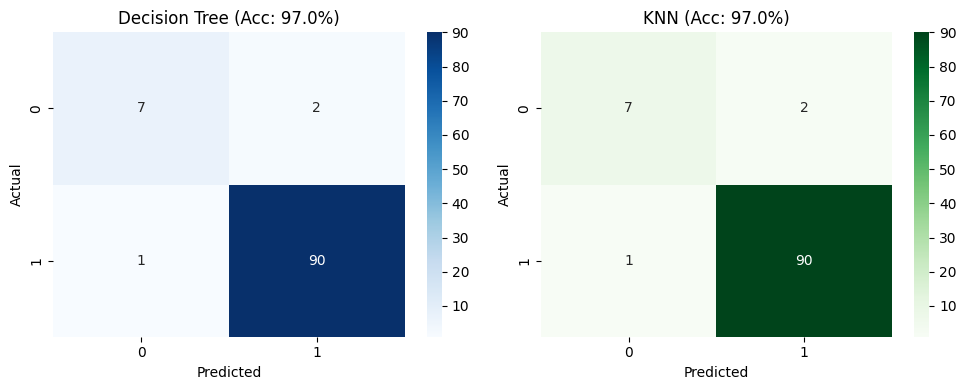

In [8]:
# --- Decision Tree Evaluation ---
dt_acc = accuracy_score(y_test, dt_preds)
dt_cm = confusion_matrix(y_test, dt_preds)

print(f"Decision Tree Accuracy: {dt_acc * 100:.2f}%")
print("Decision Tree Confusion Matrix:\n", dt_cm)

# --- KNN Evaluation ---
knn_acc = accuracy_score(y_test, knn_preds)
knn_cm = confusion_matrix(y_test, knn_preds)

print(f"\nKNN Accuracy: {knn_acc * 100:.2f}%")
print("KNN Confusion Matrix:\n", knn_cm)

# Optional: Plotting Confusion Matrices
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.heatmap(dt_cm, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title(f'Decision Tree (Acc: {dt_acc*100:.1f}%)')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

sns.heatmap(knn_cm, annot=True, fmt='d', cmap='Greens', ax=axes[1])
axes[1].set_title(f'KNN (Acc: {knn_acc*100:.1f}%)')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()